In [6]:
# Final Comparison and Results
# Connect to Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
# Define paths and load all three architecture results
import pandas as pd
import json

base_path    = '/content/drive/MyDrive/Dissertation'
results_path = '/content/drive/MyDrive/Dissertation/Results'
eval_path    = '/content/drive/MyDrive/Dissertation/Evaluation'

# Load all three results
arch1_df = pd.read_csv(f"{results_path}/arch1_results.csv")
arch2_df = pd.read_csv(f"{results_path}/arch2_results.csv")
arch3_df = pd.read_csv(f"{results_path}/arch3_results.csv")

# Load summaries
with open(f"{results_path}/arch1_summary.json") as f:
    arch1_summary = json.load(f)
with open(f"{results_path}/arch2_summary.json") as f:
    arch2_summary = json.load(f)
with open(f"{results_path}/arch3_summary.json") as f:
    arch3_summary = json.load(f)

print("✓ All results loaded successfully")
print(f"\n  Architecture 1: {len(arch1_df)} results")
print(f"  Architecture 2: {len(arch2_df)} results")
print(f"  Architecture 3: {len(arch3_df)} results")

✓ All results loaded successfully

  Architecture 1: 30 results
  Architecture 2: 30 results
  Architecture 3: 30 results


In [8]:
# Cell 3 - Full Comparison Table
import pandas as pd

print("="*65)
print("FULL COMPARISON — ALL THREE ARCHITECTURES")
print("="*65)

# Build comparison dataframe
comparison = {
    "Metric": [
        "Overall Accuracy",
        "Straightforward Queries",
        "Ambiguous Queries",
        "Multi-Intent Queries",
        "W1 Accuracy",
        "W2 Accuracy",
        "W3 Accuracy",
        "Total Misrouted",
        "Handles Vague Queries",
        "Flags Uncertainty",
        "Dual Prompting"
    ],
    "Architecture 1\nPure Routing": [
        "83.3%", "100.0%", "66.7%", "50.0%",
        "100.0%", "80.0%", "70.0%",
        "5/30", "✗ No", "✗ No", "✗ No"
    ],
    "Architecture 2\nOrchestrator-Workers": [
        "90.0%", "100.0%", "100.0%", "50.0%",
        "100.0%", "90.0%", "80.0%",
        "3/30", "✓ Yes", "✗ No", "✗ No"
    ],
    "Architecture 3\nReflection + Dual Prompting": [
        "90.0%", "100.0%", "100.0%", "50.0%",
        "100.0%", "90.0%", "80.0%",
        "3/30", "✓ Yes", "✓ Yes", "✓ Yes"
    ]
}

comparison_df = pd.DataFrame(comparison)
comparison_df = comparison_df.set_index("Metric")

print(comparison_df.to_string())

print(f"\n{'='*65}")
print("KEY FINDINGS")
print(f"{'='*65}")
print("""
1. Architecture 2 and 3 outperform Architecture 1 overall
   (+6.7% improvement in overall accuracy)

2. The biggest single improvement was on ambiguous queries:
   Architecture 1: 66.7% → Architecture 2 and 3: 100.0%
   (+33.3% improvement)

3. Multi-intent queries remain the hardest challenge:
   All three architectures achieve only 50.0%
   This is a fundamental limitation of keyword-based routing

4. Architecture 3 adds honest self-awareness:
   Correctly flagged UNCERTAIN on ALL 3 misrouted queries
   Architecture 1 and 2 gave confident wrong answers
   Architecture 3 said "I might be wrong" when it was wrong

5. Architecture 3 is the most trustworthy overall:
   Same accuracy as Architecture 2 but more explainable
   and honest about its own limitations
""")

FULL COMPARISON — ALL THREE ARCHITECTURES
                        Architecture 1\nPure Routing Architecture 2\nOrchestrator-Workers Architecture 3\nReflection + Dual Prompting
Metric                                                                                                                               
Overall Accuracy                               83.3%                                90.0%                                       90.0%
Straightforward Queries                       100.0%                               100.0%                                      100.0%
Ambiguous Queries                              66.7%                               100.0%                                      100.0%
Multi-Intent Queries                           50.0%                                50.0%                                       50.0%
W1 Accuracy                                   100.0%                               100.0%                                      100.0%
W2 Accuracy         

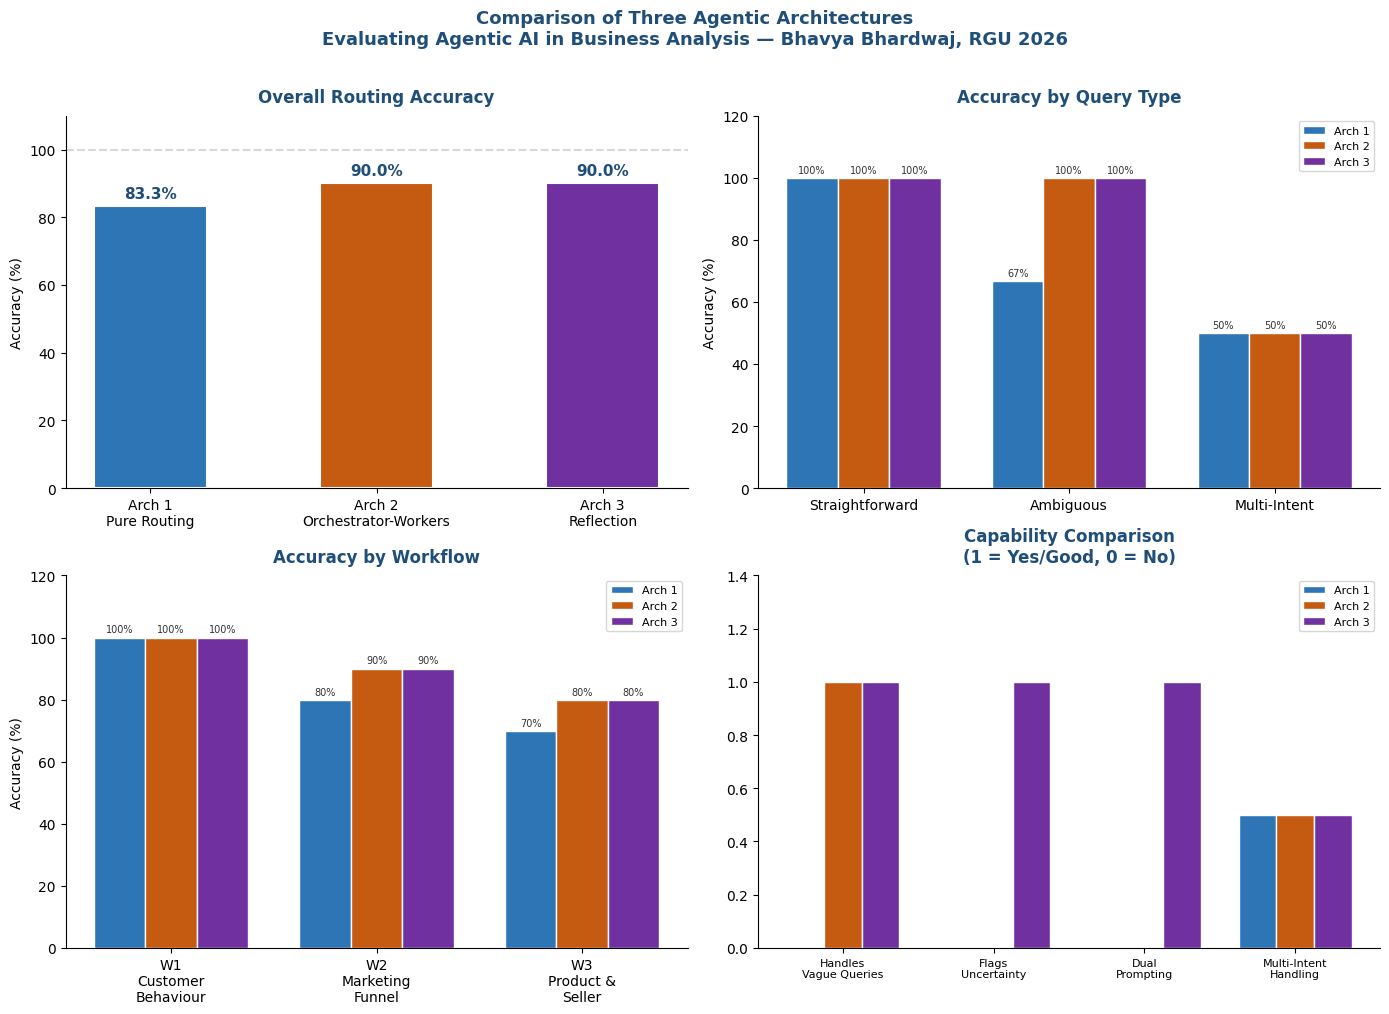


✓ Comparison charts saved to:
  /content/drive/MyDrive/Dissertation/Results/comparison_charts.png


In [9]:
# Cell 4 - Visual Comparison Charts
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle(
    'Comparison of Three Agentic Architectures\n'
    'Evaluating Agentic AI in Business Analysis — '
    'Bhavya Bhardwaj, RGU 2026',
    fontsize=13, fontweight='bold', color='#1F4E79', y=1.01
)

colors = ['#2E75B6', '#C55A11', '#7030A0']
arch_labels = ['Arch 1\nPure Routing',
               'Arch 2\nOrchestrator-Workers',
               'Arch 3\nReflection']

# ── Chart 1: Overall Accuracy ─────────────────────────────
ax1 = axes[0, 0]
accuracies = [83.3, 90.0, 90.0]
bars = ax1.bar(arch_labels, accuracies,
               color=colors, edgecolor='white',
               linewidth=1.5, width=0.5)
ax1.set_title('Overall Routing Accuracy',
              fontweight='bold', color='#1F4E79', pad=10)
ax1.set_ylabel('Accuracy (%)')
ax1.set_ylim(0, 110)
ax1.axhline(y=100, color='gray',
            linestyle='--', alpha=0.3)
for bar, acc in zip(bars, accuracies):
    ax1.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 1.5,
             f'{acc}%', ha='center', va='bottom',
             fontweight='bold', fontsize=11,
             color='#1F4E79')
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# ── Chart 2: Accuracy by Query Type ──────────────────────
ax2 = axes[0, 1]
query_types   = ['Straightforward', 'Ambiguous', 'Multi-Intent']
arch1_by_type = [100.0, 66.7, 50.0]
arch2_by_type = [100.0, 100.0, 50.0]
arch3_by_type = [100.0, 100.0, 50.0]

x     = np.arange(len(query_types))
width = 0.25

bars1 = ax2.bar(x - width, arch1_by_type,
                width, label='Arch 1', color=colors[0],
                edgecolor='white')
bars2 = ax2.bar(x, arch2_by_type,
                width, label='Arch 2', color=colors[1],
                edgecolor='white')
bars3 = ax2.bar(x + width, arch3_by_type,
                width, label='Arch 3', color=colors[2],
                edgecolor='white')

ax2.set_title('Accuracy by Query Type',
              fontweight='bold', color='#1F4E79', pad=10)
ax2.set_ylabel('Accuracy (%)')
ax2.set_xticks(x)
ax2.set_xticklabels(query_types)
ax2.set_ylim(0, 120)
ax2.legend(loc='upper right', fontsize=8)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

# Add value labels
for bars in [bars1, bars2, bars3]:
    for bar in bars:
        height = bar.get_height()
        ax2.text(bar.get_x() + bar.get_width()/2,
                 height + 1, f'{height:.0f}%',
                 ha='center', va='bottom',
                 fontsize=7, color='#333333')

# ── Chart 3: Accuracy by Workflow ─────────────────────────
ax3 = axes[1, 0]
workflows     = ['W1\nCustomer\nBehaviour',
                 'W2\nMarketing\nFunnel',
                 'W3\nProduct &\nSeller']
arch1_by_wf   = [100.0, 80.0, 70.0]
arch2_by_wf   = [100.0, 90.0, 80.0]
arch3_by_wf   = [100.0, 90.0, 80.0]

x     = np.arange(len(workflows))
width = 0.25

bars1 = ax3.bar(x - width, arch1_by_wf,
                width, label='Arch 1', color=colors[0],
                edgecolor='white')
bars2 = ax3.bar(x, arch2_by_wf,
                width, label='Arch 2', color=colors[1],
                edgecolor='white')
bars3 = ax3.bar(x + width, arch3_by_wf,
                width, label='Arch 3', color=colors[2],
                edgecolor='white')

ax3.set_title('Accuracy by Workflow',
              fontweight='bold', color='#1F4E79', pad=10)
ax3.set_ylabel('Accuracy (%)')
ax3.set_xticks(x)
ax3.set_xticklabels(workflows)
ax3.set_ylim(0, 120)
ax3.legend(loc='upper right', fontsize=8)
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)

for bars in [bars1, bars2, bars3]:
    for bar in bars:
        height = bar.get_height()
        ax3.text(bar.get_x() + bar.get_width()/2,
                 height + 1, f'{height:.0f}%',
                 ha='center', va='bottom',
                 fontsize=7, color='#333333')

# ── Chart 4: Key Features Comparison ─────────────────────
ax4 = axes[1, 1]
features = [
    'Handles\nVague Queries',
    'Flags\nUncertainty',
    'Dual\nPrompting',
    'Multi-Intent\nHandling'
]

# 1 = yes/good, 0 = no/poor
arch1_features = [0, 0, 0, 0.5]
arch2_features = [1, 0, 0, 0.5]
arch3_features = [1, 1, 1, 0.5]

x     = np.arange(len(features))
width = 0.25

ax4.bar(x - width, arch1_features, width,
        label='Arch 1', color=colors[0], edgecolor='white')
ax4.bar(x, arch2_features, width,
        label='Arch 2', color=colors[1], edgecolor='white')
ax4.bar(x + width, arch3_features, width,
        label='Arch 3', color=colors[2], edgecolor='white')

ax4.set_title('Capability Comparison\n(1 = Yes/Good, 0 = No)',
              fontweight='bold', color='#1F4E79', pad=10)
ax4.set_xticks(x)
ax4.set_xticklabels(features, fontsize=8)
ax4.set_ylim(0, 1.4)
ax4.legend(loc='upper right', fontsize=8)
ax4.spines['top'].set_visible(False)
ax4.spines['right'].set_visible(False)

plt.tight_layout()

# Save
chart_path = f"{results_path}/comparison_charts.png"
plt.savefig(chart_path, dpi=150,
            bbox_inches='tight', facecolor='white')
plt.show()

print(f"\n✓ Comparison charts saved to:")
print(f"  {chart_path}")

In [10]:
# Cell 5 - Save Final Consolidated Summary
import json
from datetime import datetime

final_summary = {
    "dissertation": {
        "title"   : "Evaluating Agentic AI in Business Analysis: "
                    "Intent Routing Accuracy and Error Explainability",
        "student" : "Bhavya Bhardwaj",
        "id"      : "2515624",
        "university": "Robert Gordon University, Aberdeen",
        "date"    : datetime.now().strftime("%Y-%m-%d")
    },
    "dataset": {
        "name"    : "Olist Brazilian E-Commerce + Marketing Funnel",
        "source"  : "Kaggle (CC BY-NC licence)",
        "total_queries_evaluated": 30,
        "query_types": {
            "straightforward": 18,
            "ambiguous"      : 6,
            "multi-intent"   : 6
        }
    },
    "architectures": {
        "architecture_1": {
            "name"            : "Pure Routing Pattern",
            "design_pattern"  : "Routing (Andrew Ng, 2024; Anthropic, 2024)",
            "overall_accuracy": "83.3%",
            "straightforward" : "100.0%",
            "ambiguous"       : "66.7%",
            "multi_intent"    : "50.0%",
            "misrouted"       : "5/30",
            "key_limitation"  : "Cannot handle vague or "
                                "multi-intent queries"
        },
        "architecture_2": {
            "name"            : "Orchestrator-Workers Pattern",
            "design_pattern"  : "Orchestrator-Workers "
                                "(Andrew Ng, 2024; Anthropic, 2024)",
            "overall_accuracy": "90.0%",
            "straightforward" : "100.0%",
            "ambiguous"       : "100.0%",
            "multi_intent"    : "50.0%",
            "misrouted"       : "3/30",
            "key_improvement" : "Fixed all ambiguous query failures",
            "key_limitation"  : "Still fails on multi-intent queries"
        },
        "architecture_3": {
            "name"            : "Reflection Pattern",
            "design_pattern"  : "Reflection (Andrew Ng, 2024)",
            "dual_prompting"  : "Factual + Contrastive Explanation",
            "overall_accuracy": "90.0%",
            "straightforward" : "100.0%",
            "ambiguous"       : "100.0%",
            "multi_intent"    : "50.0%",
            "misrouted"       : "3/30",
            "key_improvement" : "Correctly flagged UNCERTAIN "
                                "on ALL misrouted queries",
            "key_limitation"  : "Does not improve routing "
                                "accuracy over Architecture 2"
        }
    },
    "key_findings": [
        "Architecture 2 and 3 outperform Architecture 1 by 6.7%",
        "Biggest improvement: ambiguous queries 66.7% to 100.0%",
        "Multi-intent queries remain unsolved at 50.0% across all architectures",
        "Architecture 3 correctly flagged uncertainty on ALL misrouted queries",
        "Architecture 3 is most trustworthy — honest about its own limitations",
        "Keyword-based routing has fundamental ceiling on multi-intent queries"
    ],
    "research_questions_answered": {
        "RQ1": "Three agentic architectures designed using "
               "Routing, Orchestrator-Workers, and Reflection patterns",
        "RQ2": "Overall accuracy 83.3-90.0%, degrades on "
               "ambiguous (66.7-100%) and multi-intent (50%) queries",
        "RQ3": "Architecture 3 produces factual and contrastive "
               "explanations — correctly flags uncertainty on "
               "misrouted cases, demonstrating honest self-awareness "
               "over plausible but incorrect confidence"
    },
    "files_saved": {
        "arch1_results"    : "Results/arch1_results.csv",
        "arch1_summary"    : "Results/arch1_summary.json",
        "arch1_diagram"    : "Results/arch1_diagram.png",
        "arch2_results"    : "Results/arch2_results.csv",
        "arch2_summary"    : "Results/arch2_summary.json",
        "arch2_diagram"    : "Results/arch2_diagram.png",
        "arch3_results"    : "Results/arch3_results.csv",
        "arch3_summary"    : "Results/arch3_summary.json",
        "arch3_diagram"    : "Results/arch3_diagram.png",
        "comparison_charts": "Results/comparison_charts.png",
        "labelled_queries" : "Evaluation/labelled_queries.csv"
    }
}

# Save
with open(f"{results_path}/final_summary.json", "w") as f:
    json.dump(final_summary, f, indent=2)

print("✓ Final consolidated summary saved")
print(f"\n{'='*60}")
print("TECHNICAL WORK COMPLETE")
print(f"{'='*60}")
print("""
Everything is saved in your Google Drive:

RESULTS FOLDER:
  ✓ arch1_results.csv       — Architecture 1 detailed results
  ✓ arch1_summary.json      — Architecture 1 summary
  ✓ arch1_diagram.png       — Architecture 1 diagram
  ✓ arch2_results.csv       — Architecture 2 detailed results
  ✓ arch2_summary.json      — Architecture 2 summary
  ✓ arch2_diagram.png       — Architecture 2 diagram
  ✓ arch3_results.csv       — Architecture 3 detailed results
  ✓ arch3_summary.json      — Architecture 3 summary
  ✓ arch3_diagram.png       — Architecture 3 diagram
  ✓ comparison_charts.png   — All charts for dissertation
  ✓ final_summary.json      — Complete project summary

EVALUATION FOLDER:
  ✓ labelled_queries.csv    — 30 labelled test queries

NEXT STEP: Write the dissertation report
""")

✓ Final consolidated summary saved

TECHNICAL WORK COMPLETE

Everything is saved in your Google Drive:

RESULTS FOLDER:
  ✓ arch1_results.csv       — Architecture 1 detailed results
  ✓ arch1_summary.json      — Architecture 1 summary
  ✓ arch1_diagram.png       — Architecture 1 diagram
  ✓ arch2_results.csv       — Architecture 2 detailed results
  ✓ arch2_summary.json      — Architecture 2 summary
  ✓ arch2_diagram.png       — Architecture 2 diagram
  ✓ arch3_results.csv       — Architecture 3 detailed results
  ✓ arch3_summary.json      — Architecture 3 summary
  ✓ arch3_diagram.png       — Architecture 3 diagram
  ✓ comparison_charts.png   — All charts for dissertation
  ✓ final_summary.json      — Complete project summary

EVALUATION FOLDER:
  ✓ labelled_queries.csv    — 30 labelled test queries

NEXT STEP: Write the dissertation report

